# Bilgi Tabanı: Hastalıkların Ayırt Edici Belirtileri
Symptom2Disease metinlerinden, her hastalığı diğerlerinden en iyi ayıran belirtiler **chi-kare (χ²) testi** ile çıkarılır.
Sonuç chatbotta iki yerde kullanılır:
1. Bot emin değilse aday hastalıkları ayırt eden belirtileri sorar.
2. "What is malaria?" gibi sorulara veri setine dayalı belirti bilgisi verir.

In [1]:
import os, sys, json, warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.feature_selection import chi2

FIG = "../results/figures/"
TAB = "../results/tables/"
silver = pd.read_csv("../data/silver/symptom_silver.csv")
print(silver.shape)

(1153, 3)


## İki yardımcı sözlük
- **GENEL:** Belirti olmayan ama metinlerde sık geçen kelimeler ("experiencing", "lately", "really"...). Bunlar elenir.
- **GÖSTERİM:** Lemmatize edilmiş terimleri kullanıcıya gösterilecek okunabilir ifadeye çevirir ("behind eye" → "pain behind the eyes"). `None` olanlar belirti olarak gösterilmez.
Terimlerin **seçimi tamamen veriden** gelir; bu sözlükler sadece okunabilirlik içindir.

In [2]:
GENEL = {
    "experiencing", "experience", "feel", "feeling", "feels", "also", "lot", "really", "like", "past",
    "week", "day", "time", "get", "getting", "often", "bit", "hard", "especially", "even", "much",
    "constantly", "constant", "recently", "lately", "since", "make", "making", "made", "last", "around",
    "sometimes", "occasionally", "frequently", "severe", "bad", "terrible", "without", "go", "going",
    "rest", "different", "accompanied", "morning", "night", "resemble", "producing", "persistent",
    "anything", "almost", "low", "high", "period", "long", "lose", "upper", "near", "change", "touch",
    "mild", "thick", "body", "pain", "ache", "area", "part", "started", "keep", "noticed", "seem",
    "whole", "quite", "due", "able", "well", "new", "one", "two", "know", "look", "little", "difficulty",
    "ca", "scurring", "scurrying", "arm",
}

GOSTERIM = {
    "blackhead": "blackheads", "pimple": "pimples", "pu": "pus-filled spots", "rash skin": "skin rash", "sensitive": "sensitive skin",
    "eye": "itchy or watery eyes", "sore throat": "sore throat", "lip": "swollen lips", "sneeze": "sneezing", "swell": "swelling",
    "walking": "difficulty walking", "joint": "joint pain", "stiff": "stiffness", "move": "pain when moving", "weak neck": "weak neck muscles",
    "mucoid": "mucus when coughing", "sputum": "thick sputum", "cough": "cough", "breathing": "difficulty breathing", "fever": "fever",
    "neck hurt": "neck pain", "back": "back pain", "weakness": "weakness", "limb": "weak arms or legs",
    "red spot": "red spots on the skin", "lost appetite": "loss of appetite", "lymph node": "swollen lymph nodes", "spreading": "spreading rash", "causing": None,
    "sinus": "sinus pressure", "sneezing": "sneezing", "congested": "congestion", "stuffy": "stuffy nose", "cold": None,
    "behind eye": "pain behind the eyes", "developed rash": "rash",
    "palpitation": "palpitations", "healing": "slow-healing wounds", "mouth throat": "dry mouth and throat", "infection": "frequent infections", "foggy": "foggy vision",
    "anus": "pain around the anus", "stool": "changes in stool", "restroom": None, "bowel": "painful bowel movements", "bleeding": "bleeding",
    "lightheaded": "lightheadedness", "dry": None, "chest": None, "trouble": None, "skin": "skin rash",
    "patch": "scaly patches", "bump": "bumps on the skin", "lump": "lumps under the skin", "rashy": None, "red bumpy": None,
    "heartburn": "heartburn", "eating": "discomfort after eating", "food": None, "sour": "sour taste in the mouth", "throat": "burning throat",
    "headache chest": "headache with chest pain", "dizziness": "dizziness", "focus": "trouble concentrating", "concentrate": None, "balance": "loss of balance",
    "sore": "sores", "face": "sores on the face", "nose": "sores around the nose", "fluid": "fluid-filled blisters", "lesion": "skin lesions",
    "lost weight": "weight loss", "yellow": "yellow skin or eyes", "skin turned": None, "urine": "dark urine", "dark": None,
    "nausea muscle": "nausea and muscle pain", "perspiring": "heavy sweating", "chill": "chills", "headache": "headache", "itching": "itching",
    "visual": "visual disturbances", "vision": "blurred vision", "indigestion": "indigestion", "irritability": "irritability", "disturbance": None,
    "bloating": "bloating", "acidic": "acid taste", "abdomen": "upper abdominal pain", "bloated": None,
    "heart": "racing heart", "phlegm": "phlegm", "brownish": "brownish mucus", "racing": None, "sweating": "sweating",
    "nail": "nail changes", "elbow": "rash on elbows", "dent": "dents in nails", "peeling": "peeling skin", "knee": "rash on knees",
    "constipation": "constipation", "diarrhea": "diarrhea", "belly": "belly pain", "abdominal": "abdominal pain", "vomiting": "vomiting",
    "pee": "frequent urination", "urinate": "burning when urinating", "urge": "strong urge to urinate", "odour": "strong-smelling urine", "blood": "blood in urine",
    "vein": "visible veins", "calf": "calf pain", "leg": "leg pain", "vessel": "swollen blood vessels", "cramp": "leg cramps",
}

In [3]:
vec = CountVectorizer(ngram_range=(1, 2), min_df=3, binary=True)
X = vec.fit_transform(silver["temiz_metin"])
terimler = vec.get_feature_names_out()
print("Terim sayısı (tek kelime + kelime ikilisi):", len(terimler))

Terim sayısı (tek kelime + kelime ikilisi): 2182


In [4]:
bilgi_tabani, tablo = {}, []
for hastalik in sorted(silver["label"].unique()):
    bu = (silver["label"] == hastalik).values
    skor, _ = chi2(X, bu)                                    # terim bu hastalıkla ne kadar ilişkili?
    oran_ici = np.asarray(X[bu].mean(axis=0)).ravel()        # bu hastalığın metinlerinin yüzde kaçında geçiyor
    oran_disi = np.asarray(X[~bu].mean(axis=0)).ravel()      # diğer hastalıkların metinlerinin yüzde kaçında geçiyor

    secilen = []
    for i in np.argsort(-skor):                              # en yüksek chi-kare skorundan başla
        kelimeler = terimler[i].split()
        if oran_ici[i] < 0.12 or oran_ici[i] <= oran_disi[i]:
            continue                                         # nadir ya da bu hastalığa özgü olmayan terim
        if any(k in GENEL for k in kelimeler):
            continue                                         # belirti olmayan genel kelime
        if any(set(kelimeler) & set(s["terim"].split()) for s in secilen):
            continue                                         # aynı kelimeyi tekrar seçme
        secilen.append({"terim": terimler[i], "belirti": GOSTERIM.get(terimler[i], terimler[i]),
                        "oran": round(float(oran_ici[i]), 2), "diger_oran": round(float(oran_disi[i]), 2)})
        if len(secilen) == 5:
            break
    bilgi_tabani[hastalik] = secilen
    tablo.append({"Hastalık": hastalik,
                  "Ayırt edici belirtiler (bu hastalıkta % / diğerlerinde %)":
                      ", ".join(f"{s['terim']} ({s['oran']*100:.0f}% / {s['diger_oran']*100:.0f}%)" for s in secilen)})

tablo_df = pd.DataFrame(tablo)
tablo_df.to_csv(TAB + "belirti_ayirt_edici_belirtiler.csv", index=False)
pd.set_option("display.max_colwidth", None)
tablo_df

,Hastalık,Ayırt edici belirtiler (bu hastalıkta % / diğerlerinde %)
0,Acne,"blackhead (100% / 0%), pimple (100% / 1%), pu (30% / 0%), rash skin (43% / 2%), sensitive (24% / 1%)"
1,Allergy,"eye (44% / 3%), sore throat (22% / 1%), lip (20% / 0%), sneeze (14% / 0%), swell (14% / 1%)"
2,Arthritis,"walking (76% / 1%), joint (100% / 3%), stiff (76% / 1%), move (57% / 1%), weak neck (28% / 0%)"
3,Bronchial Asthma,"mucoid (43% / 0%), sputum (35% / 0%), cough (86% / 8%), breathing (57% / 4%), fever (94% / 17%)"
4,Cervical Spondylosis,"neck hurt (59% / 0%), back (96% / 4%), weakness (67% / 2%), limb (35% / 0%), cough (86% / 8%)"
5,Chicken Pox,"red spot (37% / 1%), lost appetite (29% / 1%), lymph node (18% / 1%), spreading (14% / 1%), causing (27% / 3%)"
6,Common Cold,"sinus (41% / 0%), sneezing (31% / 1%), congested (18% / 0%), stuffy (14% / 0%), cold (20% / 0%)"
7,Dengue,"behind eye (20% / 0%), red spot (26% / 2%), developed rash (12% / 0%), lost appetite (18% / 2%), back (34% / 7%)"
8,Diabetes,"palpitation (18% / 0%), healing (16% / 0%), mouth throat (12% / 0%), infection (20% / 1%), wound (12% / 0%)"
9,Dimorphic Hemorrhoids,"anus (100% / 0%), stool (63% / 2%), restroom (37% / 0%), bowel (37% / 0%), bleeding (24% / 0%)"


In [5]:
with open("../data/chatbot/hastalik_belirtileri.json", "w", encoding="utf-8") as f:
    json.dump(bilgi_tabani, f, ensure_ascii=False, indent=2)
print("Kaydedildi: data/chatbot/hastalik_belirtileri.json")
bilgi_tabani["Dengue"]

Kaydedildi: data/chatbot/hastalik_belirtileri.json


[{'terim': 'behind eye',
  'belirti': 'pain behind the eyes',
  'oran': 0.2,
  'diger_oran': 0.0},
 {'terim': 'red spot',
  'belirti': 'red spots on the skin',
  'oran': 0.26,
  'diger_oran': 0.02},
 {'terim': 'developed rash',
  'belirti': 'rash',
  'oran': 0.12,
  'diger_oran': 0.0},
 {'terim': 'lost appetite',
  'belirti': 'loss of appetite',
  'oran': 0.18,
  'diger_oran': 0.02},
 {'terim': 'back', 'belirti': 'back pain', 'oran': 0.34, 'diger_oran': 0.07}]

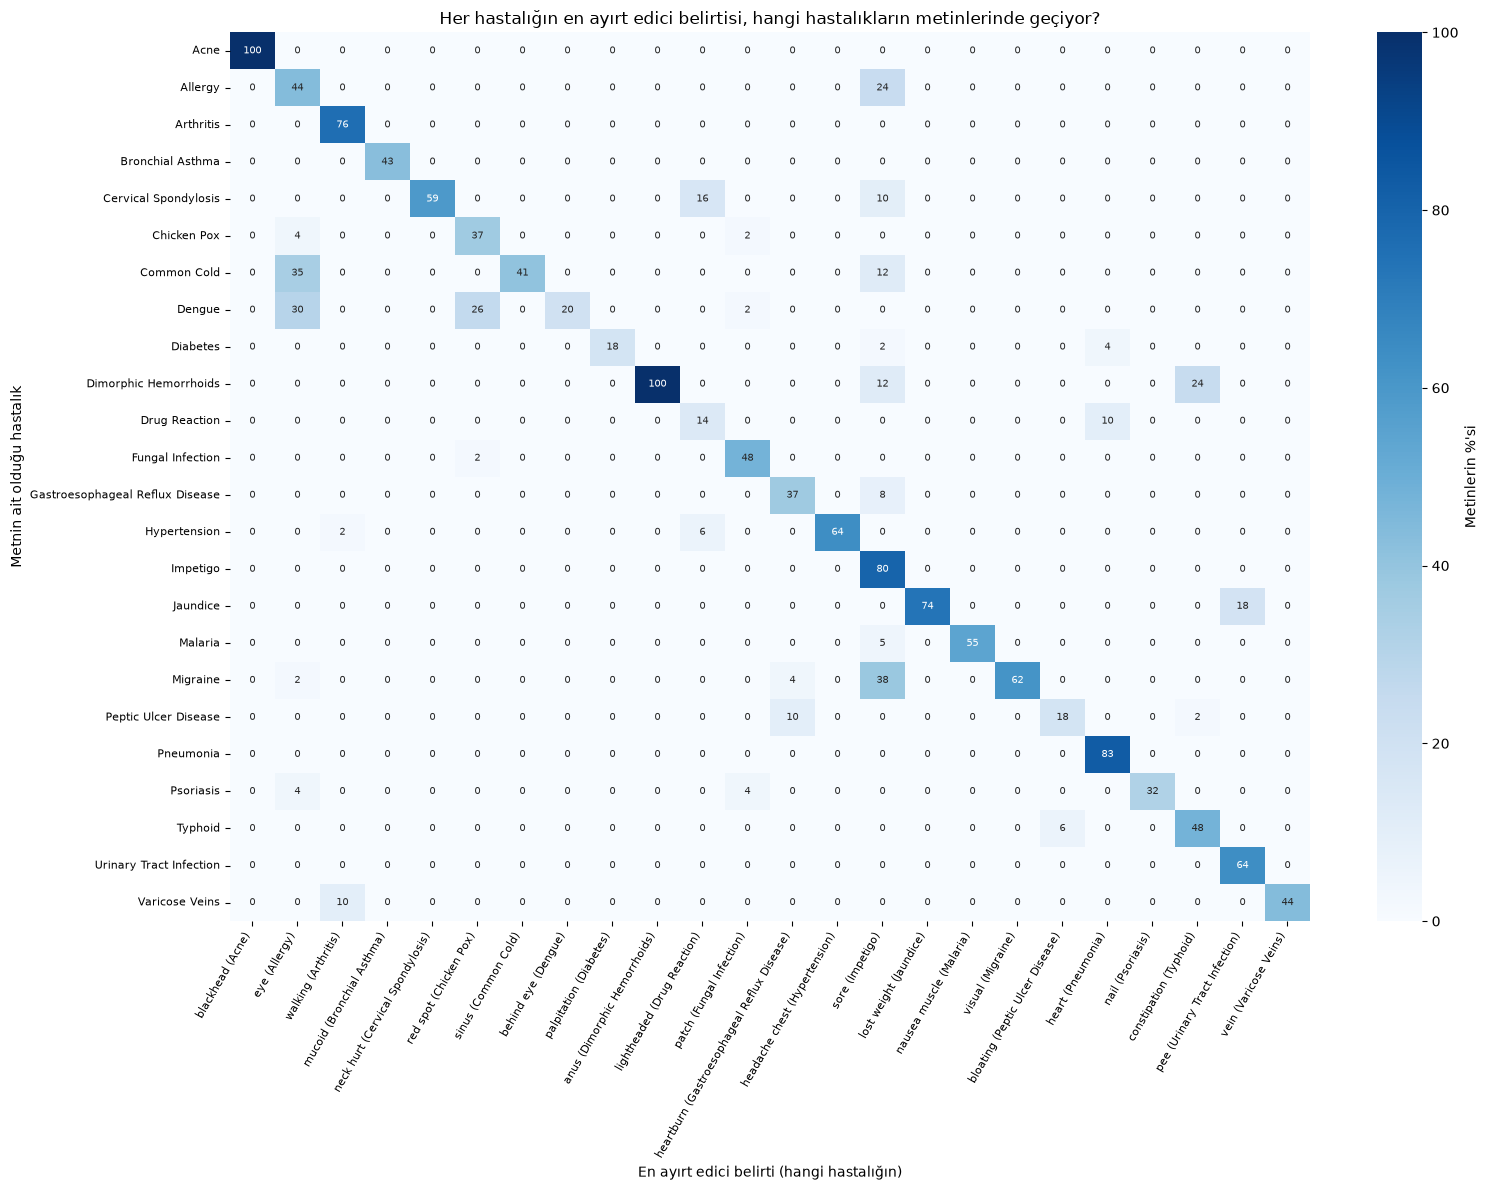

In [6]:
hastaliklar = list(bilgi_tabani)
sutun_idx = {t: i for i, t in enumerate(terimler)}
ust_terim = {h: bilgi_tabani[h][0]["terim"] for h in hastaliklar}   # her hastalığın 1 numaralı belirtisi

matris = pd.DataFrame(index=hastaliklar, columns=[f"{ust_terim[h]} ({h})" for h in hastaliklar], dtype=float)
for satir in hastaliklar:
    bu = (silver["label"] == satir).values
    for h in hastaliklar:
        matris.loc[satir, f"{ust_terim[h]} ({h})"] = X[bu][:, sutun_idx[ust_terim[h]]].mean() * 100

plt.figure(figsize=(16, 12))
sns.heatmap(matris, cmap="Blues", annot=True, fmt=".0f", cbar_kws={"label": "Metinlerin %'si"}, annot_kws={"size": 7})
plt.title("Her hastalığın en ayırt edici belirtisi, hangi hastalıkların metinlerinde geçiyor?")
plt.xlabel("En ayırt edici belirti (hangi hastalığın)"); plt.ylabel("Metnin ait olduğu hastalık")
plt.xticks(rotation=60, ha="right", fontsize=8); plt.yticks(fontsize=8)
plt.tight_layout(); plt.savefig(FIG + "belirti_06_ayirt_edici_belirtiler.png", dpi=150); plt.show()